# Parte 2 — Análise exploratória e explanatória (AVD)

Rede de hyperlinks entre subreddits (Stanford SNAP, `soc-redditHyperlinks-body.tsv`).

1. Proposta e pergunta de pesquisa
2. Carregamento dos dados
3. Exploração dos dados: estrutura, tipos e qualidade
4. Visualizações exploratórias
5. Visualizações explanatórias
6. Distribuição e outliers dos graus
7. Resposta à pergunta de pesquisa

As figuras são salvas em `out/parte2/`. O dataset deve estar em `data/dataset_parte2/`
(`python scripts/download_reddit_dataset.py`).

In [1]:
# [IA] Claude Code (Opus 5.5) – conversão dos scripts de AVD para este notebook
import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

# Executa a partir da raiz do repositório, onde ficam data/, src/ e out/.
ROOT = Path.cwd().resolve()
while not (ROOT / "requirements.txt").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.parte2.loader import (
    load_reddit_dataset,
    aggregate_interactions,
)

DATASET_PATH = Path("data/dataset_parte2/soc-redditHyperlinks-body.tsv")

OUTPUT_DIR = Path("out/parte2")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# [IA] Claude Code (Opus 5.5) – estilo visual comum e formatação numérica pt-BR
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter

plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.titleweight": "semibold",
    "axes.titlepad": 12,
    "axes.labelsize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.alpha": 0.25,
    "legend.frameon": False,
})


def pct(value):
    """Porcentagem com vírgula decimal: 91.8 -> '91,8%'."""
    return f"{value:.1f}".replace(".", ",") + "%"


def milhar(value):
    """Inteiro com ponto de milhar: 9188 -> '9.188'."""
    return f"{int(value):,}".replace(",", ".")


thousands = FuncFormatter(lambda v, _: milhar(v))


# [IA] Claude Code (Opus 5.5) – jitter para as dispersões de graus (opção escolhida pelo grupo)
from matplotlib.scale import SymmetricalLogTransform

# Mesma escala dos eixos das dispersões.
SYMLOG = dict(base=10, linthresh=1, linscale=0.4)
_to_axis = SymmetricalLogTransform(**SYMLOG)
_from_axis = _to_axis.inverted()

JITTER_MAX = 0.06  # deslocamento máximo, em unidades da escala do eixo


def _axis(values):
    return _to_axis.transform(np.asarray(values, dtype=float))


def jitter(values, seed=42):
    """Espalha pontos de graus iguais numa nuvem pequena, só na posição desenhada.

    Os graus são inteiros e milhares de subreddits caem nas mesmas
    coordenadas. O deslocamento é feito na escala do eixo (symlog), então a
    nuvem tem o mesmo tamanho visual em todo o gráfico, e nunca passa da
    metade da distância até o grau vizinho. A semente fixa deixa a figura
    reprodutível. Os cálculos (91,8%, outliers etc.) usam os valores originais.
    """
    values = np.asarray(values, dtype=float)
    pos = _axis(values)
    gap = np.minimum(_axis(values + 1) - pos, pos - _axis(values - 1))
    spread = np.minimum(JITTER_MAX, 0.45 * gap)
    rng = np.random.default_rng(seed)
    return _from_axis.transform(pos + rng.uniform(-1, 1, size=len(values)) * spread)


def midpoint(a, b):
    """Ponto a meio caminho entre dois graus, na escala do eixo."""
    return float(_from_axis.transform((_axis([a]) + _axis([b])) / 2)[0])


JITTER_NOTE = "Pontos levemente deslocados para separar subreddits com graus iguais."

# Marcas dos eixos das dispersões: só potências de 10, para não poluir.
DEGREE_TICKS_X = [0, 1, 10, 100, 1000]
DEGREE_TICKS_Y = [0, 1, 10, 100, 1000]


def clean_degree_axes(ax):
    """Eixos limpos para as dispersões de graus: escala symlog, poucas marcas,
    só grade horizontal clara."""
    ax.set_xscale("symlog", **SYMLOG)
    ax.set_yscale("symlog", **SYMLOG)
    ax.xaxis.set_major_locator(plt.FixedLocator(DEGREE_TICKS_X))
    ax.yaxis.set_major_locator(plt.FixedLocator(DEGREE_TICKS_Y))
    for axis in (ax.xaxis, ax.yaxis):
        axis.set_major_formatter(thousands)
        axis.set_minor_locator(plt.NullLocator())
    ax.set_xlim(-0.4, 2000)
    ax.set_ylim(-0.4, 2800)
    ax.grid(False)
    ax.grid(True, axis="y", color="#e6e6e6", linewidth=0.8)
    ax.tick_params(length=0, colors="#444444")
    for side in ("left", "bottom"):
        ax.spines[side].set_color("#999999")

## 1. Proposta e pergunta de pesquisa

### Proposta do dataset

O grupo escolheu o dataset **Reddit Hyperlink Network** com o objetivo de analisar como diferentes subreddits se relacionam por meio de hyperlinks direcionados entre comunidades. Cada subreddit é representado como um vértice do grafo, enquanto os hyperlinks representam arestas direcionadas entre uma comunidade de origem e uma comunidade de destino.

A escolha do dataset foi motivada pelo interesse em observar a estrutura dessas interações e compreender como as comunidades se conectam dentro da rede. Além da direção das conexões, o dataset também possui informação de sentimento associada aos hyperlinks, permitindo representar as relações entre subreddits por meio de um grafo dirigido e ponderado.

### Pergunta de pesquisa

**Como os subreddits se relacionam e interagem entre si por meio de hyperlinks dentro da rede do Reddit?**

## 2. Carregamento dos dados

`df` guarda as interações originais (uma linha por hyperlink). `aggregated` soma
`LINK_SENTIMENT` por par dirigido origem → destino, como no grafo da Parte 2.

In [2]:
df = load_reddit_dataset(DATASET_PATH)
aggregated = aggregate_interactions(df)

## 3. Exploração dos dados: estrutura, tipos e qualidade

### 3.1 Dimensões, colunas e tipos

In [3]:
print("Shape:", df.shape)
print("Linhas:", len(df))
print("Colunas:", len(df.columns))
print("\nColunas:", df.columns.tolist())
print("\nTipos:")
print(df.dtypes)

Shape: (286561, 6)
Linhas: 286561
Colunas: 6

Colunas: ['SOURCE_SUBREDDIT', 'TARGET_SUBREDDIT', 'POST_ID', 'TIMESTAMP', 'LINK_SENTIMENT', 'PROPERTIES']

Tipos:
SOURCE_SUBREDDIT      str
TARGET_SUBREDDIT      str
POST_ID               str
TIMESTAMP             str
LINK_SENTIMENT      int64
PROPERTIES            str
dtype: object


In [4]:
df.head()

,SOURCE_SUBREDDIT,TARGET_SUBREDDIT,POST_ID,TIMESTAMP,LINK_SENTIMENT,PROPERTIES
0,leagueoflegends,teamredditteams,1u4nrps,2013-12-31 16:39:58,1,"345.0,298.0,0.75652173913,0.0173913043478,0.08..."
1,theredlion,soccer,1u4qkd,2013-12-31 18:18:37,-1,"101.0,98.0,0.742574257426,0.019801980198,0.049..."
2,inlandempire,bikela,1u4qlzs,2014-01-01 14:54:35,1,"85.0,85.0,0.752941176471,0.0235294117647,0.082..."
3,nfl,cfb,1u4sjvs,2013-12-31 17:37:55,1,"1124.0,949.0,0.772241992883,0.0017793594306,0...."
4,playmygame,gamedev,1u4w5ss,2014-01-01 02:51:13,1,"715.0,622.0,0.777622377622,0.00699300699301,0...."


### 3.2 Valores ausentes e duplicatas

In [5]:
print("Valores ausentes:")
print(df.isna().sum())

print("\nDuplicatas exatas:", df.duplicated().sum())

print("\nPOST_IDs distintos:", df["POST_ID"].nunique())
print("POST_IDs duplicados:", df["POST_ID"].duplicated().sum())

Valores ausentes:
SOURCE_SUBREDDIT    0
TARGET_SUBREDDIT    0
POST_ID             0
TIMESTAMP           0
LINK_SENTIMENT      0
PROPERTIES          0
dtype: int64



Duplicatas exatas: 0

POST_IDs distintos: 259092
POST_IDs duplicados: 27469


### 3.3 Subreddits e self-links

In [6]:
source_unicos = df["SOURCE_SUBREDDIT"].nunique()
target_unicos = df["TARGET_SUBREDDIT"].nunique()

all_subreddits = (
    set(df["SOURCE_SUBREDDIT"])
    | set(df["TARGET_SUBREDDIT"])
)

print("SOURCE_SUBREDDIT distintos:", source_unicos)
print("TARGET_SUBREDDIT distintos:", target_unicos)
print("Total de subreddits distintos (origem + destino):", len(all_subreddits))

self_links = (
    df["SOURCE_SUBREDDIT"]
    == df["TARGET_SUBREDDIT"]
).sum()

print("\nSelf-links:", self_links)

SOURCE_SUBREDDIT distintos: 27863
TARGET_SUBREDDIT distintos: 20606
Total de subreddits distintos (origem + destino): 35776



Self-links: 0


### 3.4 Sentimento dos hyperlinks (`LINK_SENTIMENT`)

In [7]:
print("Distribuição de LINK_SENTIMENT:")
print(
    df["LINK_SENTIMENT"]
    .value_counts(dropna=False)
    .sort_index()
)

print("\nValores distintos:", sorted(df["LINK_SENTIMENT"].dropna().unique()))
print("Interações negativas:", (df["LINK_SENTIMENT"] == -1).sum())
print("Interações positivas:", (df["LINK_SENTIMENT"] == 1).sum())

Distribuição de LINK_SENTIMENT:
LINK_SENTIMENT
-1     21070
 1    265491
Name: count, dtype: int64

Valores distintos: [np.int64(-1), np.int64(1)]
Interações negativas: 21070
Interações positivas: 265491


### 3.5 Período temporal

In [8]:
timestamps = pd.to_datetime(
    df["TIMESTAMP"],
    errors="coerce",
)

print("Datas inválidas:", timestamps.isna().sum())
print("Data inicial:", timestamps.min())
print("Data final:", timestamps.max())

Datas inválidas: 0
Data inicial: 2013-12-31 16:39:58
Data final: 2017-04-30 16:58:21


### 3.6 Pares origem → destino e multiplicidade

In [9]:
pair_counts = (
    df.groupby([
        "SOURCE_SUBREDDIT",
        "TARGET_SUBREDDIT",
    ])
    .size()
    .sort_values(ascending=False)
)

repeated_rows = pair_counts[pair_counts > 1]

print("Pares dirigidos distintos:", len(pair_counts))
print("Pares repetidos:", (pair_counts > 1).sum())
print("Interações representadas por pares repetidos:", repeated_rows.sum())
print("Multiplicidade máxima:", pair_counts.max())

pair_sentiments = (
    df.groupby([
        "SOURCE_SUBREDDIT",
        "TARGET_SUBREDDIT",
    ])["LINK_SENTIMENT"]
    .nunique()
)

print("Pares com interações positivas e negativas:", (pair_sentiments > 1).sum())

Pares dirigidos distintos: 137821


Pares repetidos: 33987
Interações representadas por pares repetidos: 182727
Multiplicidade máxima: 548
Pares com interações positivas e negativas: 7205


In [10]:
# Pares origem → destino mais repetidos
pair_counts.head(20)

SOURCE_SUBREDDIT     TARGET_SUBREDDIT
trendingsubreddits   changelog           548
streetfighter        sf4                 279
buildapc             buildapcforme       244
mushroomkingdom      gamesale            243
bluejackets          bluejacketsgwg      223
summonerschool       leagueoflegends     220
atletico             soccer              211
writingprompts       askreddit           208
fireemblemcasual     fireemblem          206
babymetal            sakuragakuin        188
acturnips            ratemymayor         187
outoftheloop         askreddit           186
techsupport          buildapc            183
longhornnation       cfb                 180
cig_rca              starcitizen         175
buildapc             techsupport         168
iama                 books               166
brokehugs            christianity        165
argentinacirclejerk  argentina           164
crashwhowritings     writingprompts      161
dtype: int64

### 3.7 Grafo agregado e pesos

In [11]:
print("Arestas agregadas:", len(aggregated))

print("\nPesos agregados (WEIGHT):")
print(aggregated["WEIGHT"].describe())

positivos = (aggregated["WEIGHT"] > 0).sum()
negativos = (aggregated["WEIGHT"] < 0).sum()
zeros = (aggregated["WEIGHT"] == 0).sum()

print("\nPesos positivos:", positivos)
print("Pesos negativos:", negativos)
print("Pesos zero:", zeros)

Arestas agregadas: 137821

Pesos agregados (WEIGHT):
count    137821.000000
mean          1.773467
std           4.909331
min         -29.000000
25%           1.000000
50%           1.000000
75%           1.000000
max         548.000000
Name: WEIGHT, dtype: float64

Pesos positivos: 128050
Pesos negativos: 7657
Pesos zero: 2114


## 4. Visualizações exploratórias

### 4.1 Exploratória 1 — Grau de saída × grau de entrada

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


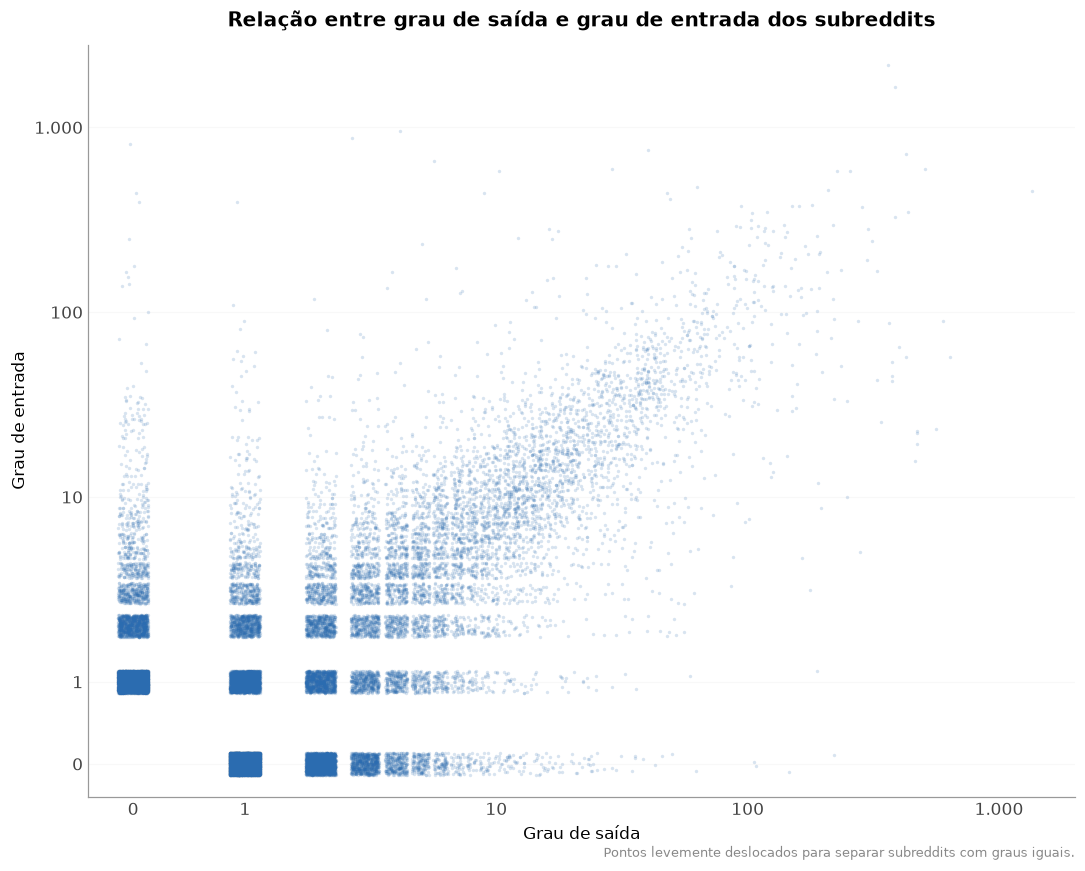

In [12]:
out_degree = (
    aggregated
    .groupby("SOURCE_SUBREDDIT")
    .size()
    .rename("grau_saida")
)

in_degree = (
    aggregated
    .groupby("TARGET_SUBREDDIT")
    .size()
    .rename("grau_entrada")
)

degrees = (
    pd.concat([out_degree, in_degree], axis=1)
    .fillna(0)
    .reset_index()
    .rename(columns={"index": "subreddit"})
)

fig, ax = plt.subplots(figsize=(10, 8))

# [IA] Claude Code (Opus 5.5) – aparência limpa: pontos pequenos e leves, posição com jitter
# [IA] ChatGPT – 12: apoio ao diagrama de dispersão de graus em escala symlog.
ax.scatter(
    jitter(degrees["grau_saida"], seed=1),
    jitter(degrees["grau_entrada"], seed=2),
    s=5,
    color="#2b6cb0",
    alpha=0.18,
    linewidths=0,
)

ax.set_xlabel("Grau de saída")
ax.set_ylabel("Grau de entrada")
ax.set_title(
    "Relação entre grau de saída e grau de entrada dos subreddits"
)

# [IA] Claude Code (Opus 5.5) – eixos com poucas marcas e só grade horizontal clara
clean_degree_axes(ax)

ax.text(
    1.0, -0.08, JITTER_NOTE,
    transform=ax.transAxes, ha="right", fontsize=8.5, color="#888888",
)

plt.tight_layout()

plt.savefig(
    "out/parte2/scatter_graus_symlog.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Exploratória 1 — Relação entre grau de saída e grau de entrada

**1. O que o gráfico mostra:**  
Cada ponto representa um subreddit da rede de hyperlinks do Reddit. O eixo X representa o **grau de saída**, isto é, a quantidade de comunidades distintas para as quais o subreddit possui conexões de saída. O eixo Y representa o **grau de entrada**, correspondente à quantidade de comunidades distintas das quais ele recebe conexões. Os dois eixos utilizam escala `symlog`, permitindo visualizar simultaneamente valores iguais a zero, graus baixos e valores que chegam à ordem dos milhares.

**2. O que eu observei:**  
A grande maioria dos subreddits concentra-se em graus baixos, principalmente entre 0 e 10. Também existem pontos sobre os eixos, correspondentes a comunidades que apresentam apenas grau de entrada ou apenas grau de saída. A partir dos graus mais elevados, observa-se uma associação positiva aparente entre as duas variáveis: subreddits com maior grau de saída também tendem a apresentar maior grau de entrada. Nas extremidades da distribuição aparecem poucos subreddits com graus muito superiores aos da maioria da rede.

**3. Por que usamos scatter plot:**  
O scatter plot foi utilizado porque estamos investigando a relação entre **duas variáveis quantitativas**, grau de saída e grau de entrada, medidas para a mesma unidade de análise, cada subreddit. Ao representar cada comunidade como um par ordenado \((x, y)\), o gráfico permite observar simultaneamente a concentração dos dados, a relação entre as duas variáveis e a presença de valores extremos, características que seriam mais difíceis de visualizar em um gráfico destinado à análise de apenas uma variável.

### 4.2 Exploratória 2 — Interações ao longo do tempo


Primeiros meses:
   TIMESTAMP  interacoes
0 2014-01-31        4440
1 2014-02-28        4431
2 2014-03-31        5383
3 2014-04-30        4990
4 2014-05-31        5472

Últimos meses:
    TIMESTAMP  interacoes
35 2016-12-31        8230
36 2017-01-31        8794
37 2017-02-28        9015
38 2017-03-31        9409
39 2017-04-30        9188


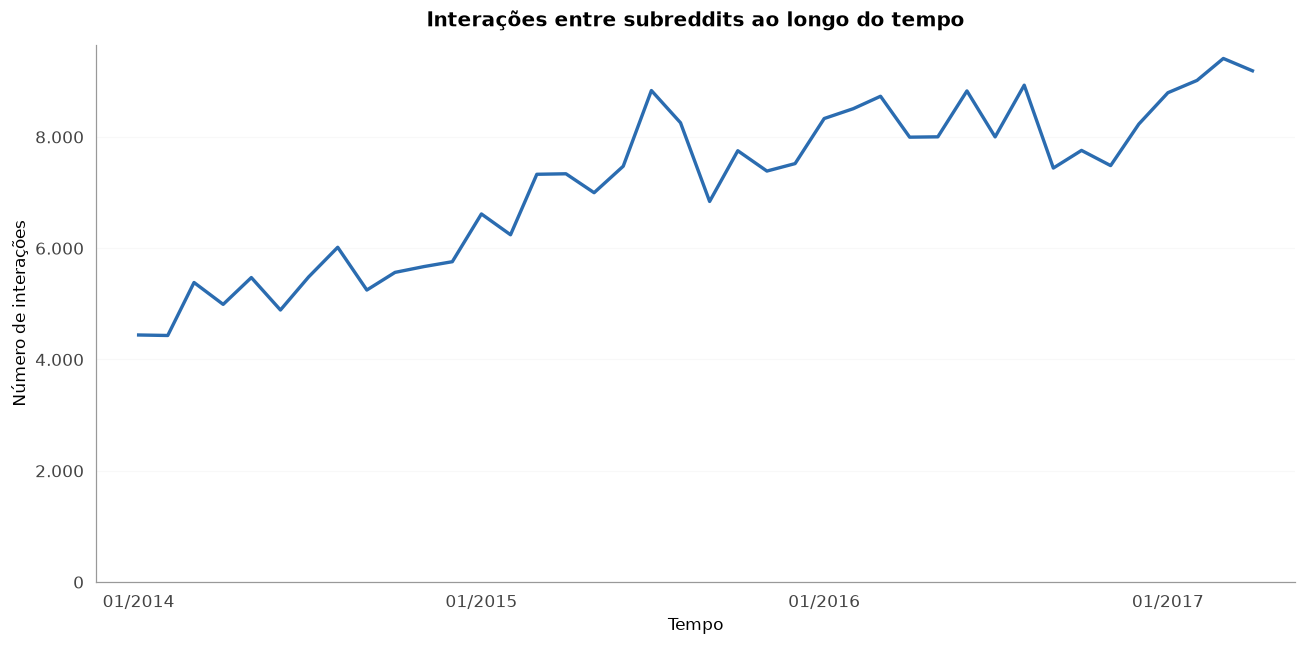

In [13]:
df["TIMESTAMP"] = pd.to_datetime(df["TIMESTAMP"])

interactions_by_month = (
    df
    .set_index("TIMESTAMP")
    .resample("ME")
    .size()
    .reset_index(name="interacoes")
)

# [IA] Claude Code (Opus 5.5) – remove dez/2013 (um único dia de coleta), como descrito na nota analítica
interactions_by_month = interactions_by_month[
    interactions_by_month["TIMESTAMP"] >= "2014-01-01"
].reset_index(drop=True)

print("\nPrimeiros meses:")
print(interactions_by_month.head())

print("\nÚltimos meses:")
print(interactions_by_month.tail())

plt.figure(figsize=(12, 6))

# [IA] Claude Code (Opus 5.5) – aparência limpa: mesma cor da dispersão, linha firme;
# [IA] ChatGPT – 13: apoio na agregação mensal e no gráfico temporal.
# cada mês desenhado no 1º dia (o resample "ME" data pelo último dia), para alinhar com as marcas do eixo
month_start = interactions_by_month["TIMESTAMP"].dt.to_period("M").dt.to_timestamp()

plt.plot(
    month_start,
    interactions_by_month["interacoes"],
    color="#2b6cb0",
    linewidth=2.2,
)

plt.xlabel("Tempo")
plt.ylabel("Número de interações")
plt.title("Interações entre subreddits ao longo do tempo")

# [IA] Claude Code (Opus 5.5) – uma marca por ano, ponto de milhar e só grade horizontal clara
ax = plt.gca()
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%m/%Y"))
ax.yaxis.set_major_formatter(thousands)
ax.set_ylim(bottom=0)
ax.set_xlim(month_start.iloc[0] - pd.Timedelta(days=45), month_start.iloc[-1] + pd.Timedelta(days=45))
ax.grid(False)
ax.grid(True, axis="y", color="#e6e6e6", linewidth=0.8)
ax.tick_params(length=0, pad=8, colors="#444444")
for side in ("left", "bottom"):
    ax.spines[side].set_color("#999999")

plt.tight_layout()

plt.savefig(
    "out/parte2/interacoes_ao_longo_do_tempo.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Exploratória 2 — Interações ao longo do tempo

**1. O que o gráfico mostra:**  
O gráfico apresenta a evolução temporal do volume de interações na rede de hyperlinks do Reddit. O eixo X representa o **tempo**, agregado por mês, cobrindo o período de **janeiro de 2014 a abril de 2017**. O eixo Y mostra a **quantidade mensal de interações** registradas entre subreddits. Dezembro de 2013 não foi considerado nessa análise temporal por representar apenas um dia de coleta, já que o dataset começa em 31 de dezembro de 2013.

**2. O que eu observei:**  
Há uma tendência geral de crescimento ao longo do período analisado, com o volume mensal passando de aproximadamente 4.000 interações no início de 2014 para valores próximos de 10.000 no início de 2017. Apesar dessa tendência de crescimento, a série apresenta oscilações mensais e alguns picos locais, especialmente em períodos de 2015, 2016 e no início de 2017.

**3. Por que usamos gráfico de linha:**  
O gráfico de linha foi utilizado porque estamos analisando a evolução de uma **variável quantitativa**, o número de interações, ao longo de uma **dimensão temporal ordenada**, os meses. A conexão sequencial entre os pontos facilita a observação da evolução da série, permitindo identificar sua direção geral, as oscilações mensais e os picos que ocorrem ao longo do período.

## 5. Visualizações explanatórias

In [14]:
def build_degrees_dataframe(aggregated):
    out_degree = (
        aggregated
        .groupby("SOURCE_SUBREDDIT")
        .size()
        .rename("grau_saida")
    )

    in_degree = (
        aggregated
        .groupby("TARGET_SUBREDDIT")
        .size()
        .rename("grau_entrada")
    )

    degrees = (
        pd.concat([out_degree, in_degree], axis=1)
        .fillna(0)
        .reset_index()
        .rename(columns={"index": "subreddit"})
    )

    return degrees

### 5.1 Explanatória 1 — Concentração dos subreddits em graus baixos

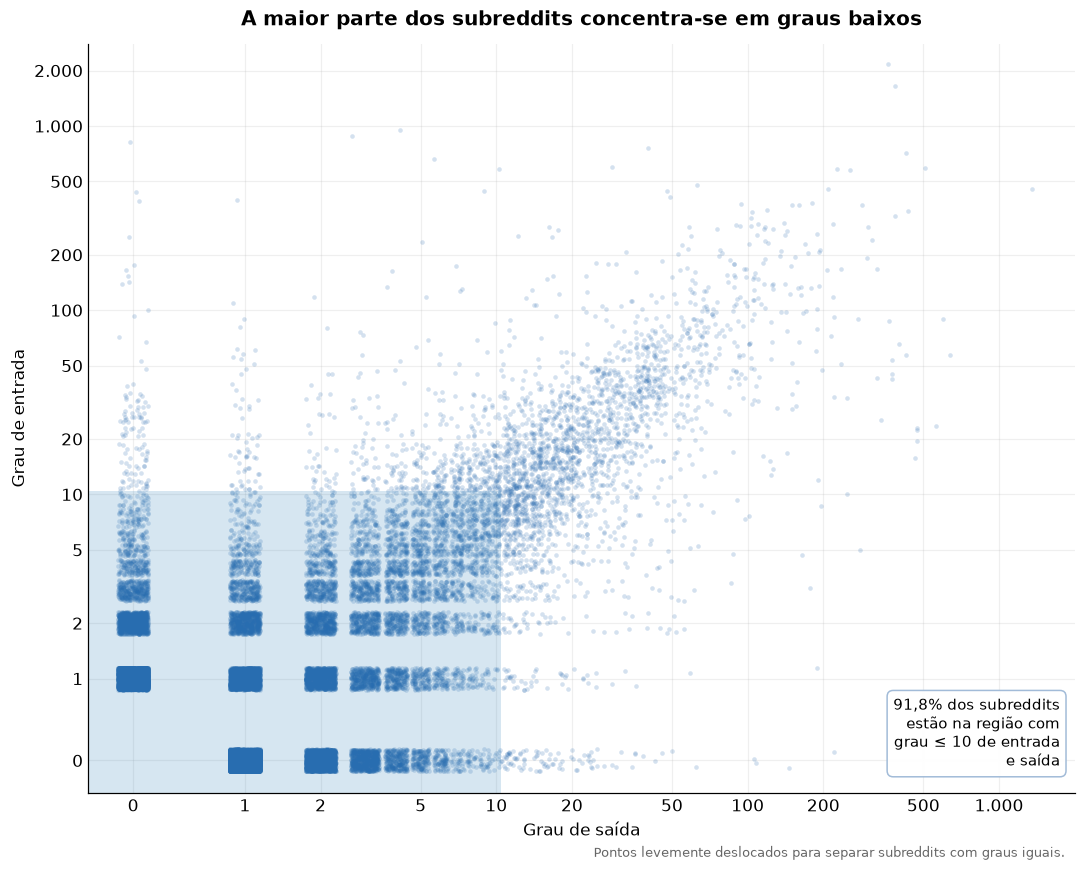

In [15]:
def explanatory_scatter_low_degree_concentration(aggregated):
    degrees = build_degrees_dataframe(aggregated)

    low_limit = 10

    low_region = degrees[
        (degrees["grau_saida"] <= low_limit)
        & (degrees["grau_entrada"] <= low_limit)
    ]

    percentage = (
        len(low_region) / len(degrees)
    ) * 100

    fig, ax = plt.subplots(figsize=(10, 7))

    # [IA] Claude Code (Opus 5.5) – aparência dos pontos igual à da exploratória 1, com jitter
    ax.scatter(
        jitter(degrees["grau_saida"], seed=1),
        jitter(degrees["grau_entrada"], seed=2),
        s=9,
        color="#2b6cb0",
        alpha=0.2,
        linewidths=0,
    )

    # [IA] ChatGPT – 14 e 49: apoio no destaque da região de graus até 10 e na justificativa discutida.
    # [IA] Claude Code (Opus 5.5) – com jitter, a borda fica a meio caminho entre os graus
    # vizinhos (entre −1 e 0, e entre low_limit e low_limit + 1), na escala do eixo,
    # para que todos os pontos de grau 0 a 10 fiquem dentro da região
    low_edge = midpoint(-1, 0)
    high_edge = midpoint(low_limit, low_limit + 1)
    highlight = Rectangle(
        (low_edge, low_edge),
        high_edge - low_edge,
        high_edge - low_edge,
        alpha=0.18,
    )
    ax.add_patch(highlight)

    ax.set_xscale("symlog")
    ax.set_yscale("symlog")

    # [IA] Claude Code (Opus 5.5) – mesma escala e marcas de eixo da exploratória 1
    ax.set_xscale("symlog", **SYMLOG)
    ax.set_yscale("symlog", **SYMLOG)
    ax.xaxis.set_major_locator(plt.FixedLocator([0, 1, 2, 5, 10, 20, 50, 100, 200, 500, 1000]))
    ax.yaxis.set_major_locator(plt.FixedLocator([0, 1, 2, 5, 10, 20, 50, 100, 200, 500, 1000, 2000]))
    for axis in (ax.xaxis, ax.yaxis):
        axis.set_major_formatter(thousands)
        axis.set_minor_locator(plt.NullLocator())
    ax.set_xlim(-0.4, 2000)
    ax.set_ylim(-0.4, 2800)
    ax.tick_params(length=0)

    ax.text(
        0.99, -0.085, JITTER_NOTE,
        transform=ax.transAxes, ha="right", fontsize=8.5, color="#666666",
    )

    ax.set_xlabel("Grau de saída")
    ax.set_ylabel("Grau de entrada")
    ax.set_title(
        "A maior parte dos subreddits concentra-se em graus baixos"
    )

    # [IA] ChatGPT – ajuste de texto e posicionamento da anotação.
    # [IA] Claude Code (Opus 5.5) – anotação no canto inferior direito, área sem pontos, com fundo opaco
    ax.text(
        0.985,
        0.03,
        (
            f"{pct(percentage)} dos subreddits\n"
            f"estão na região com\n"
            f"grau ≤ {low_limit} de entrada\n"
            "e saída"
        ),
        transform=ax.transAxes,
        fontsize=10,
        ha="right",
        va="bottom",
        bbox=dict(
            boxstyle="round,pad=0.4",
            facecolor="white",
            edgecolor="#9db8d6",
            alpha=0.95,
        ),
    )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(True, alpha=0.2)

    # [IA] Claude Code (Opus 5.5) – mesmo tamanho da exploratória 1
    fig.set_size_inches(10, 8)

    plt.tight_layout()

    plt.savefig(
        OUTPUT_DIR / "explanatoria_1_concentracao_graus.png",
        dpi=300,
        bbox_inches="tight",
    )

    plt.show()


explanatory_scatter_low_degree_concentration(aggregated)

### Explanatória 1 — Concentração dos subreddits em graus baixos

**1. O que o gráfico comunica:**  
A mensagem principal é que a maior parte dos subreddits possui poucos relacionamentos distintos com outras comunidades: **91,8% apresentam simultaneamente grau de saída menor ou igual a 10 e grau de entrada menor ou igual a 10**. Isso mostra que a grande maioria das comunidades está concentrada na região de baixos graus, enquanto apenas 8,2% dos subreddits ficam fora dessa faixa.

**2. Relação com a pergunta de pesquisa:**  
Esse resultado ajuda a responder à pergunta *“Como os subreddits se relacionam e interagem entre si por meio de hyperlinks dentro da rede do Reddit?”* ao mostrar que a quantidade de comunidades distintas com as quais cada subreddit se conecta não é distribuída de maneira uniforme. A maior parte apresenta poucos relacionamentos de entrada e saída, enquanto uma parcela menor alcança graus mais elevados.

**3. Por que destacamos a região até grau 10:**  
O retângulo sombreado foi utilizado para direcionar a atenção para a região em que se encontra a maior parte dos subreddits. Como a escala `symlog` permite representar simultaneamente graus muito baixos e valores elevados, o destaque ajuda o leitor a identificar rapidamente a faixa de interesse sem desconsiderar o restante da distribuição.

**4. Por que colocamos a porcentagem diretamente no gráfico:**  
Em um gráfico de dispersão com milhares de pontos, existe sobreposição entre observações que possuem graus iguais ou semelhantes. Por isso, apenas observar a densidade visual não permite estimar com precisão quantos subreddits pertencem à região destacada. A anotação de **91,8%** transforma essa concentração em uma medida quantitativa direta e facilita a compreensão da principal mensagem do gráfico.

**5. Diferença para a exploratória:**  
A visualização exploratória foi utilizada para observar a distribuição geral dos graus de entrada e saída e identificar padrões presentes nos dados. Já a explanatória direciona a atenção para um achado específico dessa exploração: a concentração de **91,8% dos subreddits na região em que os graus de entrada e saída são menores ou iguais a 10**. O destaque da região e a anotação percentual tornam essa mensagem mais direta para o leitor.

### 5.2 Explanatória 2 — Crescimento das interações ao longo do tempo

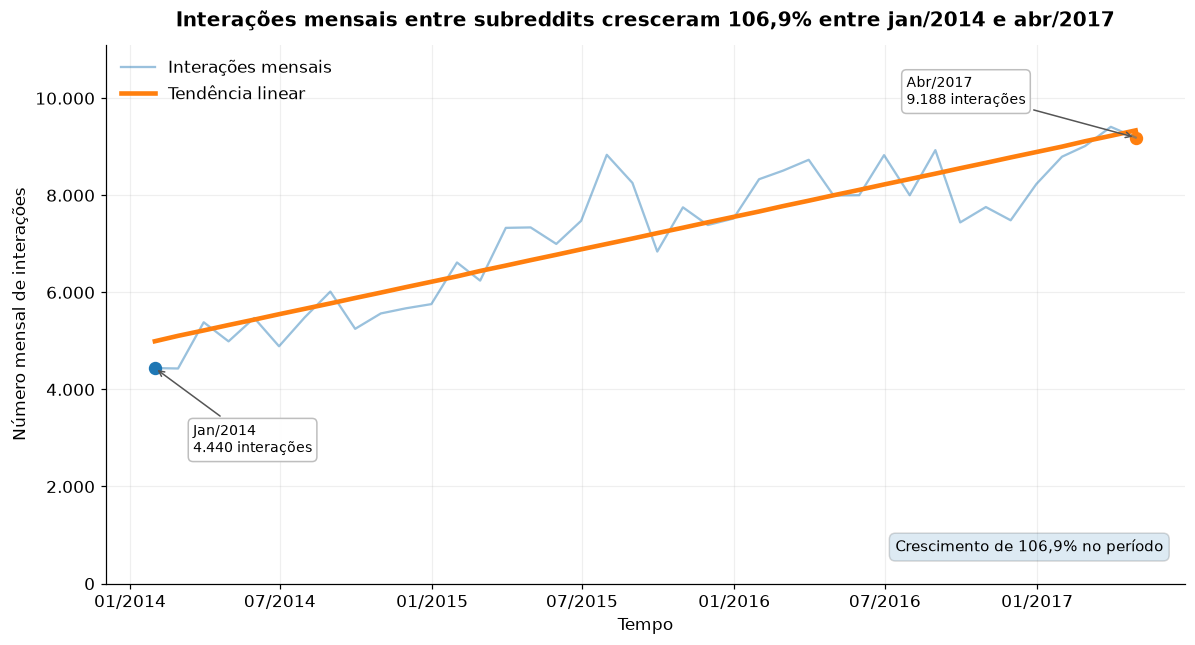

In [16]:
def explanatory_time_growth(df):
    df = df.copy()

    df["TIMESTAMP"] = pd.to_datetime(
        df["TIMESTAMP"],
        errors="coerce",
    )

    df = df.dropna(subset=["TIMESTAMP"])

    monthly = (
        df
        .set_index("TIMESTAMP")
        .resample("ME")
        .size()
        .reset_index(name="interacoes")
    )

    # Dezembro/2013 é excluído porque o dataset começa em 31/12/2013.
    monthly = monthly[
        (monthly["TIMESTAMP"] >= "2014-01-01")
        & (monthly["TIMESTAMP"] <= "2017-04-30")
    ].copy()

    monthly["indice"] = range(len(monthly))

    start_value = monthly.iloc[0]["interacoes"]
    end_value = monthly.iloc[-1]["interacoes"]

    growth_pct = (
        (end_value - start_value) / start_value
    ) * 100

    # [IA] ChatGPT – 15: apoio na apresentação da tendência e dos extremos da série.
    # [IA] ChatGPT – suporte de sintaxe para cálculo da tendência linear.
    coefficients = np.polyfit(
        monthly["indice"],
        monthly["interacoes"],
        1,
    )

    trend = (
        coefficients[0] * monthly["indice"]
        + coefficients[1]
    )

    fig, ax = plt.subplots(figsize=(11, 6))

    ax.plot(
        monthly["TIMESTAMP"],
        monthly["interacoes"],
        linewidth=1.5,
        alpha=0.45,
        label="Interações mensais",
    )

    ax.plot(
        monthly["TIMESTAMP"],
        trend,
        linewidth=3,
        label="Tendência linear",
    )

    ax.scatter(
        monthly.iloc[0]["TIMESTAMP"],
        start_value,
        s=60,
    )

    ax.scatter(
        monthly.iloc[-1]["TIMESTAMP"],
        end_value,
        s=60,
    )

    # [IA] Claude Code (Opus 5.5) – rótulos e texto de crescimento reposicionados em áreas livres
    label_box = dict(
        boxstyle="round,pad=0.35",
        facecolor="white",
        edgecolor="#bbbbbb",
        alpha=0.95,
    )

    ax.annotate(
        f"Jan/2014\n{milhar(start_value)} interações",
        xy=(
            monthly.iloc[0]["TIMESTAMP"],
            start_value,
        ),
        xytext=(25, -55),
        textcoords="offset points",
        fontsize=9,
        bbox=label_box,
        arrowprops=dict(
            arrowstyle="->",
            color="#555555",
        ),
    )

    ax.annotate(
        f"Abr/2017\n{milhar(end_value)} interações",
        xy=(
            monthly.iloc[-1]["TIMESTAMP"],
            end_value,
        ),
        xytext=(-150, 22),
        textcoords="offset points",
        fontsize=9,
        bbox=label_box,
        arrowprops=dict(
            arrowstyle="->",
            color="#555555",
        ),
    )

    ax.text(
        0.98,
        0.06,
        f"Crescimento de {pct(growth_pct)} no período",
        transform=ax.transAxes,
        ha="right",
        fontsize=10,
        bbox=dict(
            boxstyle="round,pad=0.4",
            alpha=0.15,
        ),
    )

    # [IA] ChatGPT – ajustes finais de apresentação definidos pelo grupo.
    ax.set_ylim(bottom=0)
    # [IA] Claude Code (Opus 5.5) – espaço acima da série para o rótulo final
    ax.set_ylim(top=max(monthly["interacoes"]) * 1.18)

    ax.set_xlabel("Tempo")
    ax.set_ylabel("Número mensal de interações")
    ax.set_title(
        f"Interações mensais entre subreddits cresceram "
        f"{pct(growth_pct)} entre jan/2014 e abr/2017"
    )

    # [IA] Claude Code (Opus 5.5) – eixo de datas mm/aaaa e ponto de milhar no eixo y
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%m/%Y"))
    ax.yaxis.set_major_formatter(thousands)

    ax.legend(loc="upper left")

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(True, alpha=0.2)

    plt.tight_layout()

    plt.savefig(
        OUTPUT_DIR / "explanatoria_2_crescimento_interacoes.png",
        dpi=300,
        bbox_inches="tight",
    )

    plt.show()


explanatory_time_growth(df)

### Explanatória 2 — Crescimento das interações ao longo do tempo

**1. O que o gráfico comunica:**  
A mensagem principal é que o volume mensal de interações por hyperlinks entre subreddits **mais que dobrou** ao longo do período analisado, registrando um crescimento de **106,9%** entre janeiro de 2014 e abril de 2017. Esse resultado mostra que a quantidade mensal de hyperlinks entre comunidades aumentou de forma expressiva durante o período observado.

**2. O que eu observei:**  
O volume mensal partiu de aproximadamente 4.000 interações em janeiro de 2014 e alcançou valores superiores a 8.000 e 9.000 interações mensais no início de 2017. Apesar das oscilações e dos picos observados ao longo dos meses, a trajetória geral da série é ascendente entre o início e o fim do período analisado.

**3. Por que destacamos a linha de tendência:**  
A série mensal apresenta oscilações e picos de curto prazo que podem dificultar a percepção da direção geral dos dados. O destaque da **linha de tendência** ajuda a separar visualmente essas variações mensais do comportamento geral da série, tornando mais evidente a direção de crescimento ao longo do período.

**4. Por que destacamos início e fim:**  
Marcar explicitamente **jan/2014** e **abr/2017** com pontos e rótulos cria duas referências visuais para a comparação. Assim, o leitor consegue identificar diretamente os valores utilizados para calcular o crescimento de **106,9%**, sem depender apenas da leitura aproximada dos eixos.

**5. Diferença para a exploratória:**  
Enquanto a visualização exploratória apresenta a série temporal de forma aberta, permitindo observar a evolução, as oscilações e os picos existentes nos dados, a visualização explanatória direciona a atenção para um achado específico: o crescimento das interações ao longo do período. A linha de tendência, os pontos de início e fim e a anotação do percentual tornam essa mensagem mais direta.

## 6. Distribuição e outliers dos graus

In [17]:
# [IA] Claude Code (Opus 5.5) – gráficos de distribuição e de outliers dos graus
DEGREE_COLUMNS = {
    "grau_entrada": "Grau de entrada",
    "grau_saida": "Grau de saída",
}

COLORS = {
    "grau_entrada": "#2a78c8",
    "grau_saida": "#e07b39",
}

TOP_OUTLIERS = 5


def style_axis(ax):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(True, alpha=0.2)


def iqr_limits(values):
    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1

    return q1 - 1.5 * iqr, q3 + 1.5 * iqr


def spread_labels(values, min_gap=0.13):
    """Afasta rótulos próximos, em escala log, para não se sobreporem.

    Recebe os graus em ordem decrescente e devolve a altura de cada rótulo.
    """
    positions = []

    for value in values:
        y = np.log10(value + 1)
        if positions and positions[-1] - y < min_gap:
            y = positions[-1] - min_gap
        positions.append(y)

    return [10 ** y - 1 for y in positions]


def find_outliers(degrees):
    """Marca como outlier o subreddit acima de Q3 + 1,5·IQR em cada grau."""
    rows = []

    for column, label in DEGREE_COLUMNS.items():
        _, upper = iqr_limits(degrees[column])
        selected = degrees[degrees[column] > upper]

        for row in selected.itertuples(index=False):
            rows.append(
                {
                    "subreddit": row.subreddit,
                    "metrica": label,
                    "grau": int(getattr(row, column)),
                    "limite_superior": upper,
                }
            )

    return (
        pd.DataFrame(rows)
        .sort_values(["metrica", "grau"], ascending=[True, False])
        .reset_index(drop=True)
    )

In [18]:
degrees = build_degrees_dataframe(aggregated)

outliers = find_outliers(degrees)
outliers.to_csv(OUTPUT_DIR / "outliers_graus.csv", index=False)

print("\n=== RESUMO DOS GRAUS ===")
print(degrees[list(DEGREE_COLUMNS)].describe())

print("\n=== OUTLIERS (Q3 + 1,5·IQR) ===")
print(outliers.groupby("metrica").size())

for label in DEGREE_COLUMNS.values():
    print(f"\nTop {TOP_OUTLIERS} – {label}:")
    print(
        outliers[outliers["metrica"] == label]
        .head(TOP_OUTLIERS)[["subreddit", "grau"]]
        .to_string(index=False)
    )


=== RESUMO DOS GRAUS ===
       grau_entrada    grau_saida
count  35776.000000  35776.000000
mean       3.852331      3.852331
std       24.951518     17.490761
min        0.000000      0.000000
25%        0.000000      1.000000
50%        1.000000      1.000000
75%        2.000000      2.000000
max     2161.000000   1350.000000

=== OUTLIERS (Q3 + 1,5·IQR) ===
metrica
Grau de entrada    3717
Grau de saída      6097
dtype: int64

Top 5 – Grau de entrada:
    subreddit  grau
    askreddit  2161
         iama  1646
         pics   953
       videos   879
todayilearned   816

Top 5 – Grau de saída:
        subreddit  grau
   subredditdrama  1350
        copypasta   636
            drama   600
subredditoftheday   559
     outoftheloop   507


### 6.1 Distribuição dos graus

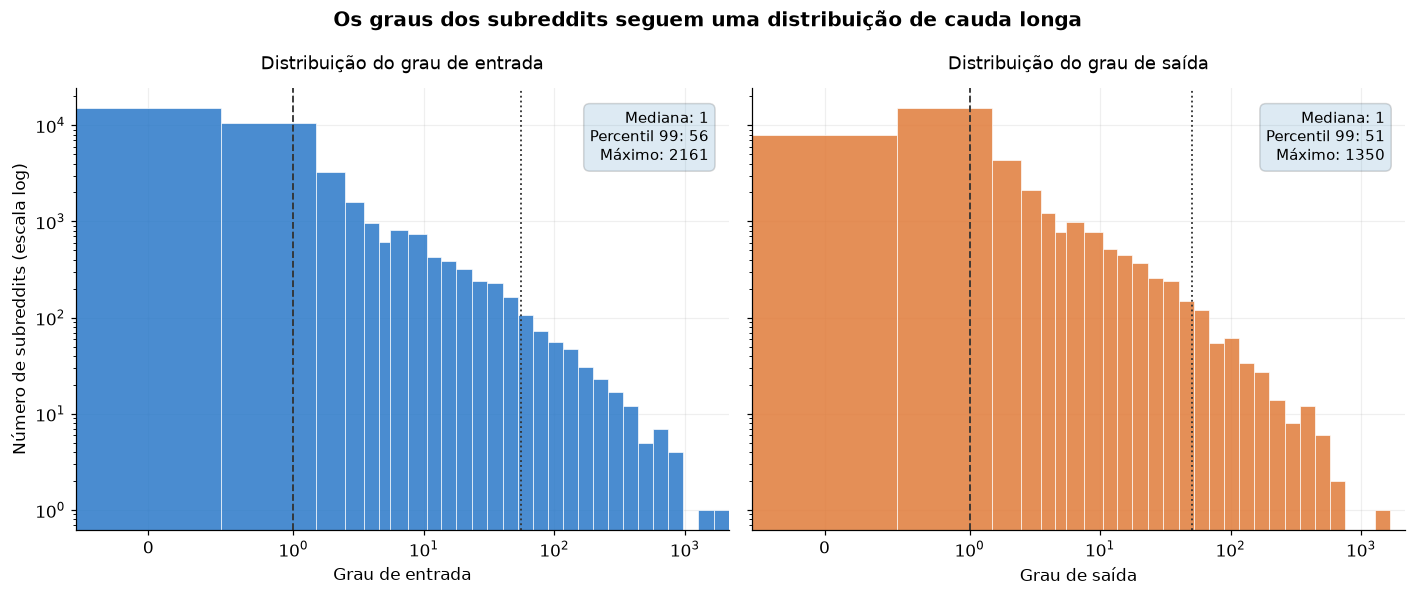

In [19]:
def distribution_chart(degrees):
    """Histograma com bins logarítmicos dos graus de entrada e saída."""
    max_degree = int(degrees[list(DEGREE_COLUMNS)].max().max())

    # Bins logarítmicos para uma distribuição de cauda longa. As bordas
    # ficam em meio-inteiros para que cada grau baixo (0, 1, 2...) tenha
    # um bin próprio, sem bins vazios entre inteiros.
    edges = np.unique(
        np.round(np.logspace(0, np.log10(max_degree + 1), 30))
    )
    bins = np.concatenate([[0], edges]) - 0.5

    fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), sharey=True)

    for ax, (column, label) in zip(axes, DEGREE_COLUMNS.items()):
        values = degrees[column]
        median = values.median()
        p99 = values.quantile(0.99)

        ax.hist(
            values,
            bins=bins,
            color=COLORS[column],
            alpha=0.85,
            edgecolor="white",
            linewidth=0.5,
        )

        ax.axvline(median, color="#333333", linestyle="--", linewidth=1.2)
        ax.axvline(p99, color="#333333", linestyle=":", linewidth=1.2)

        ax.text(
            0.97,
            0.95,
            (
                f"Mediana: {median:.0f}\n"
                f"Percentil 99: {p99:.0f}\n"
                f"Máximo: {values.max():.0f}"
            ),
            transform=ax.transAxes,
            ha="right",
            va="top",
            fontsize=10,
            bbox=dict(boxstyle="round,pad=0.4", alpha=0.15),
        )

        ax.set_xscale("symlog", linthresh=1)
        ax.set_xlim(bins[0], bins[-1])
        ax.set_yscale("log")
        ax.set_xlabel(label)
        # [IA] Claude Code (Opus 5.5) – título do painel mais leve que o título geral
        ax.set_title(f"Distribuição do {label.lower()}", fontsize=12, fontweight="normal")
        style_axis(ax)

    axes[0].set_ylabel("Número de subreddits (escala log)")

    fig.suptitle(
        "Os graus dos subreddits seguem uma distribuição de cauda longa",
        fontsize=13,
        fontweight="semibold",
    )

    plt.tight_layout()

    plt.savefig(
        OUTPUT_DIR / "distribuicao_graus.png",
        dpi=300,
        bbox_inches="tight",
    )

    plt.show()


distribution_chart(degrees)

**Nota analítica:** _a ser escrita pelo grupo (o que o gráfico mostra, o que observamos e por que este tipo de gráfico)._

### 6.2 Outliers dos graus

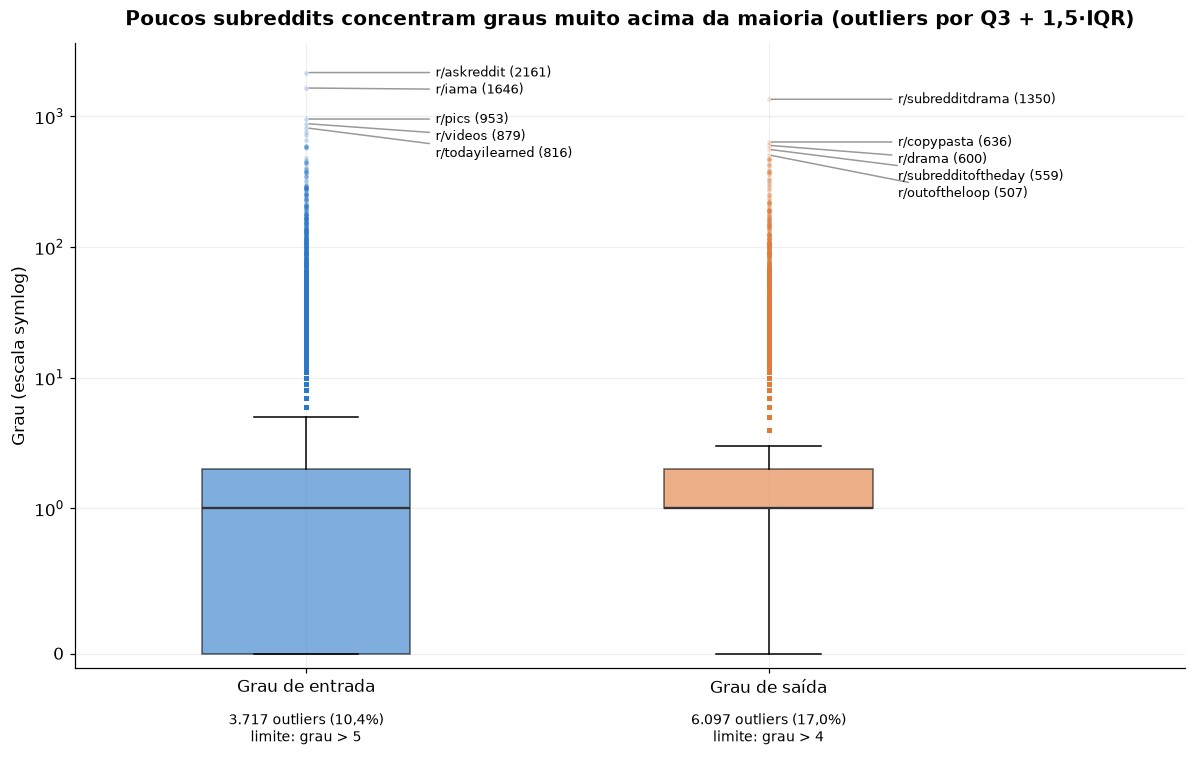

In [20]:
def outlier_chart(degrees, outliers):
    """Boxplot dos graus com os subreddits mais extremos rotulados."""
    columns = list(DEGREE_COLUMNS)

    fig, ax = plt.subplots(figsize=(11, 7))

    box = ax.boxplot(
        [degrees[column] for column in columns],
        positions=range(1, len(columns) + 1),
        widths=0.45,
        patch_artist=True,
        whis=1.5,
        flierprops=dict(
            marker="o",
            markersize=3,
            alpha=0.25,
            markeredgecolor="none",
        ),
        medianprops=dict(color="#333333", linewidth=1.5),
    )

    for patch, flier, column in zip(box["boxes"], box["fliers"], columns):
        patch.set_facecolor(COLORS[column])
        patch.set_alpha(0.6)
        flier.set_markerfacecolor(COLORS[column])

    total = len(degrees)

    for position, (column, label) in enumerate(DEGREE_COLUMNS.items(), start=1):
        subset = outliers[outliers["metrica"] == label]
        upper = iqr_limits(degrees[column])[1]
        share = len(subset) / total * 100

        # Resumo abaixo do rótulo do eixo x (x em dados, y em fração do eixo).
        ax.text(
            position,
            -0.07,
            f"{milhar(len(subset))} outliers ({pct(share)})\nlimite: grau > {upper:.0f}",
            ha="center",
            va="top",
            fontsize=9,
            transform=ax.get_xaxis_transform(),
        )

        top = subset.head(TOP_OUTLIERS)

        for row, label_y in zip(
            top.itertuples(index=False),
            spread_labels(top["grau"].tolist()),
        ):
            ax.annotate(
                f"r/{row.subreddit} ({row.grau})",
                xy=(position, row.grau),
                xytext=(position + 0.28, label_y),
                fontsize=8.5,
                va="center",
                arrowprops=dict(arrowstyle="-", alpha=0.4),
            )

    ax.set_yscale("symlog", linthresh=1)
    ax.set_ylim(bottom=-0.1)
    ax.set_xticks(range(1, len(columns) + 1))
    ax.set_xticklabels(DEGREE_COLUMNS.values())
    ax.set_xlim(0.5, len(columns) + 0.9)
    ax.set_ylabel("Grau (escala symlog)")
    ax.set_title(
        "Poucos subreddits concentram graus muito acima da maioria "
        "(outliers por Q3 + 1,5·IQR)"
    )
    style_axis(ax)

    plt.tight_layout()

    plt.savefig(
        OUTPUT_DIR / "outliers_graus.png",
        dpi=300,
        bbox_inches="tight",
    )

    plt.show()


outlier_chart(degrees, outliers)

**Nota analítica:** _a ser escrita pelo grupo (o que o gráfico mostra, o que observamos e por que este tipo de gráfico)._

## 7. Resposta à pergunta de pesquisa

A análise mostrou que **a rede de hyperlinks do Reddit apresenta uma distribuição assimétrica nas conexões entre subreddits e um aumento no volume mensal de interações ao longo do período analisado**.

O resultado de **91,8%** indica que a grande maioria dos subreddits apresenta simultaneamente **grau de entrada menor ou igual a 10 e grau de saída menor ou igual a 10**. Isso significa que a maior parte das comunidades se relaciona diretamente com uma quantidade relativamente pequena de outros subreddits.

Ao mesmo tempo, uma parcela reduzida das comunidades apresenta graus de entrada ou saída consideravelmente mais elevados, mostrando que a quantidade de conexões não está distribuída de maneira uniforme entre os vértices da rede.

Além da estrutura das conexões, a análise temporal mostrou que o volume mensal de hyperlinks entre subreddits **cresceu 106,9% entre janeiro de 2014 e abril de 2017**. Apesar das oscilações mensais, a série apresenta uma direção geral de crescimento durante o período observado.

Assim, podemos responder à pergunta de pesquisa dizendo que **os subreddits se relacionam de maneira desigual por meio de hyperlinks: a grande maioria mantém conexões diretas com poucas comunidades, enquanto uma parcela menor apresenta graus significativamente mais elevados. Além disso, a frequência mensal dessas interações aumentou ao longo do período analisado.**